# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox. The SpaceNet-5 dataset contains road labels as well as travel time. This example classifies the road travel time/speed into 3 categories: slow, medium and fast.

## Import the required packages

In [ ]:
from aitlas.datasets import SpaceNet5Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/spacenet_5/train/",
    "mode" : "multi", # multi (detecting roads and their speed) or binary (detecting roads only)
}
dataset = SpaceNet5Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 2369


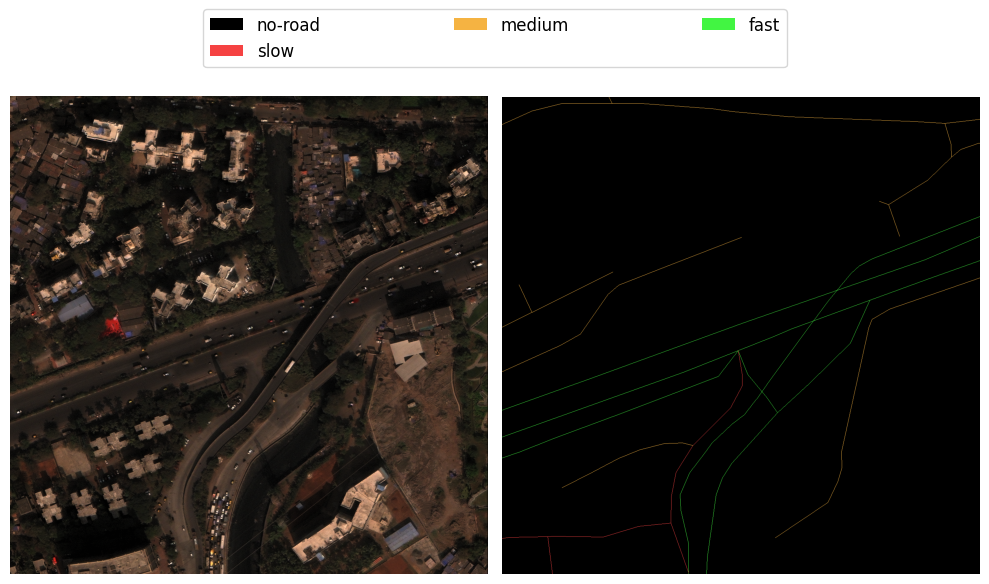

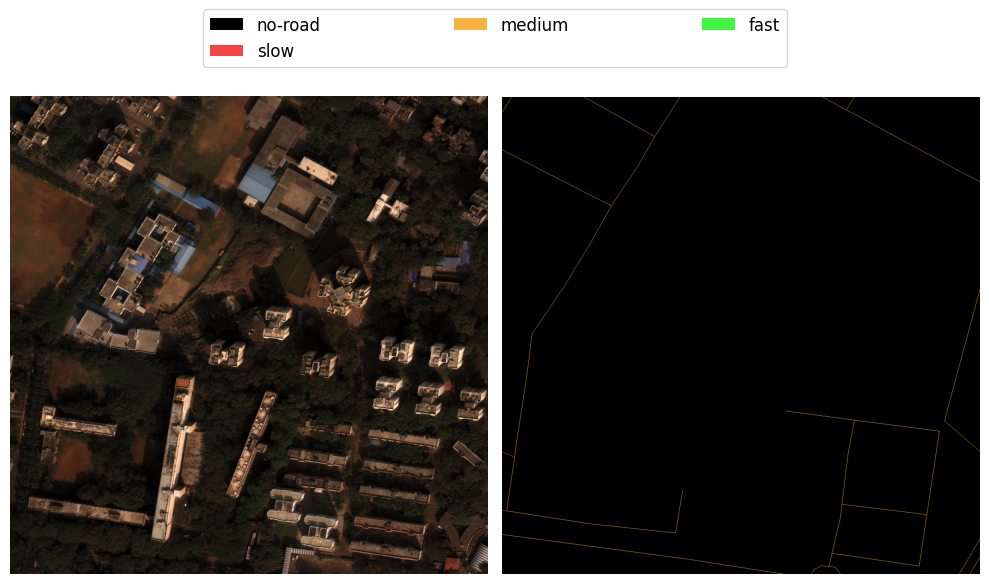

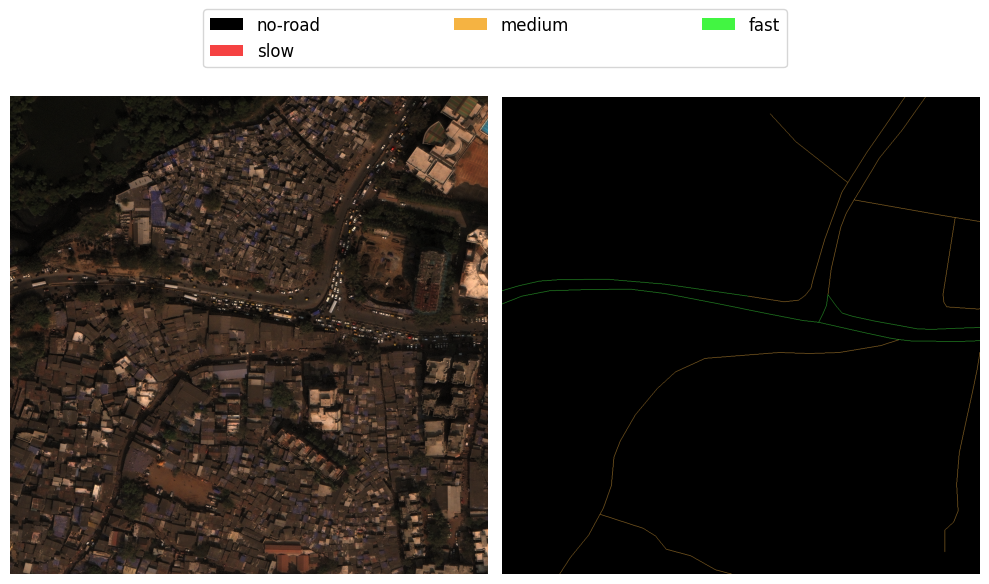

In [21]:
dataset.show_image(15);
dataset.show_image(300);
dataset.show_image(25);

In [22]:
dataset.data_distribution_table()

,Number of pixels
no-road,3.990812e+09
slow,5.147947e+06
medium,5.748469e+06
fast,1.901172e+06


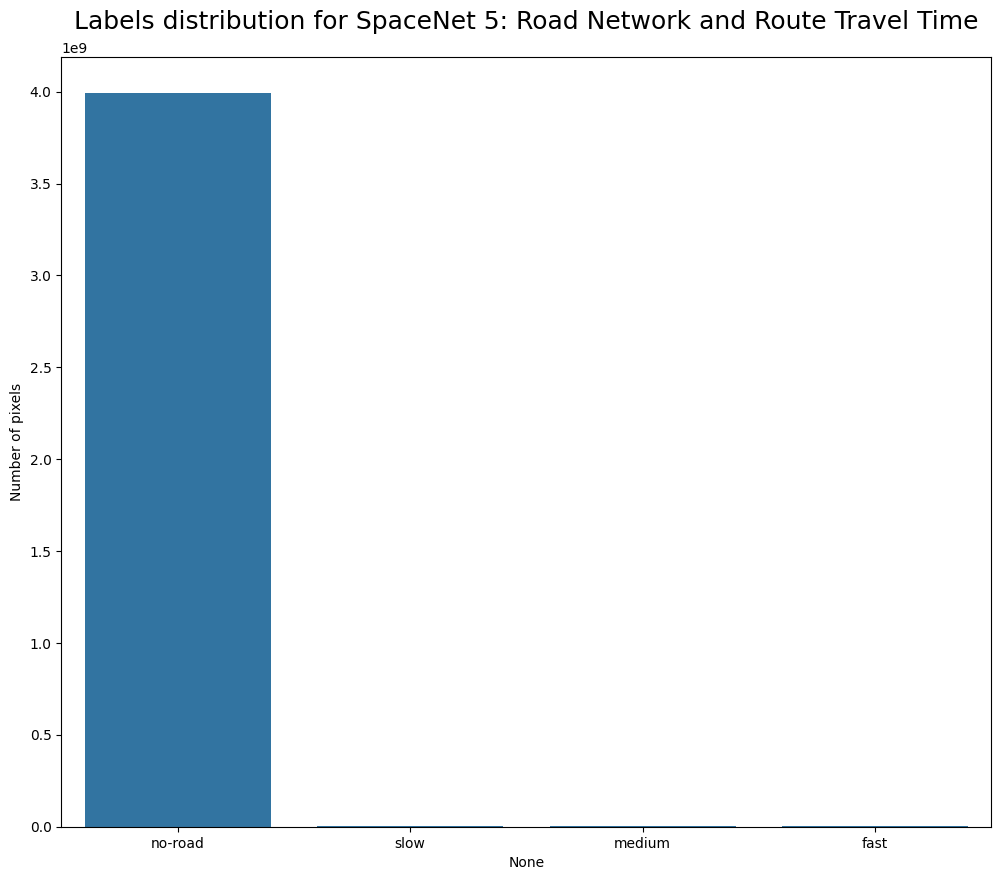

In [23]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 23,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/spacenet_5/train/",
    "mode": "multi",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SpaceNet5Dataset(train_dataset_config)

len(train_dataset)

2369

## Create the model ##

In [6]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/SpaceNet5"
model_config = {
    "num_classes": 4, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-10-14 12:21:34,497 INFO Starting training.
training: 100%|██████████| 103/103 [22:44<00:00, 13.25s/it]
2025-10-14 12:44:19,223 INFO epoch: 1, time: 1365, loss:  0.51437
testing on train set: 100%|██████████| 103/103 [23:09<00:00, 13.50s/it]
2025-10-14 13:07:30,660 INFO IOU:0.0, IOU mean:0.0, IOU per Class:[0. 0. 0. 0.]
training: 100%|██████████| 103/103 [23:00<00:00, 13.40s/it]
2025-10-14 13:30:31,124 INFO epoch: 2, time: 1381, loss:  0.33127
testing on train set: 100%|██████████| 103/103 [22:40<00:00, 13.21s/it]
2025-10-14 13:53:11,597 INFO IOU:0.04183227728762098, IOU mean:0.010458069321905244, IOU per Class:[0.04183228 0.         0.         0.        ]
training: 100%|██████████| 103/103 [23:18<00:00, 13.58s/it]
2025-10-14 14:16:30,536 INFO epoch: 3, time: 1399, loss:  0.18270
testing on train set: 100%|██████████| 103/103 [22:28<00:00, 13.09s/it]
2025-10-14 14:38:58,985 INFO IOU:0.9611247895728489, IOU mean:0.24028119739321221, IOU per Class:[0.96112479 0.         0.         0.

0.0157708705050274

## Predictions ##

2025-10-15 06:36:37,258 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet5/checkpoint.pth.tar
2025-10-15 06:36:37,542 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet5/checkpoint.pth.tar at epoch 11


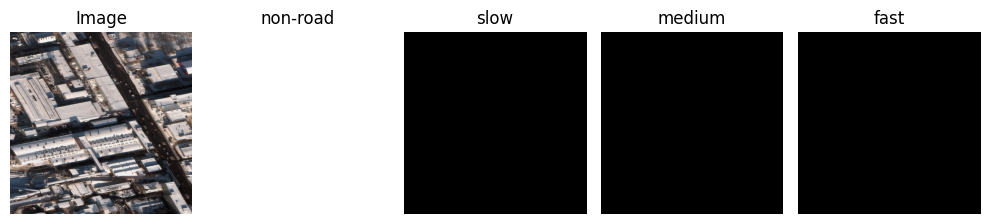

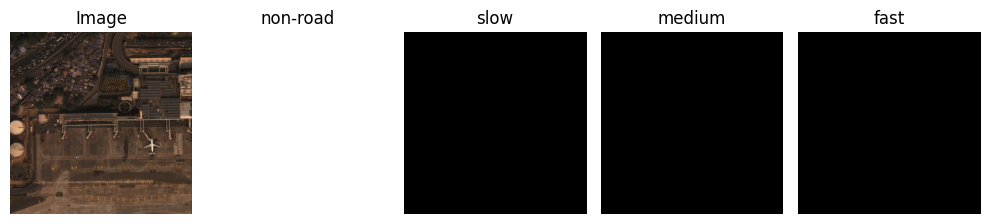

In [ ]:
model_path = "/home/dragik/data/FAIR_EO/experiments/SpaceNet5/checkpoint.pth.tar"
labels = ["non-road","slow","medium","fast"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/spacenet_5/test_public/AOI_7_Moscow/PS-RGB/SN5_roads_test_public_AOI_7_Moscow_PS-RGB_chip7.tif')
fig = model.predict_masks(image, labels, transform)
image = image_loader('/home/dragik/data/FAIR_EO/spacenet_5/test_public/AOI_8_Mumbai/PS-RGB/SN5_roads_test_public_AOI_8_Mumbai_PS-RGB_chip6.tif')
fig = model.predict_masks(image, labels, transform)